# OI Pattern Classifier - Stock Market Analysis

## Objective
This notebook implements a machine learning classifier to predict Open Interest (OI) patterns in futures and options trading data. The model analyzes price movements and open interest changes to classify market sentiment patterns.

## Key Patterns:
- **Long Build-up**: Price ↑ & OI ↑ (Bulls adding positions)
- **Short Build-up**: Price ↓ & OI ↑ (Bears adding positions)  
- **Long Unwinding**: Price ↓ & OI ↓ (Bulls exiting positions)
- **Short Covering**: Price ↑ & OI ↓ (Bears exiting positions)

## Contents:
1. Data Loading and Exploration
2. Feature Engineering
3. Model Training with Random Forest
4. Model Evaluation
5. Comparison with LazyPredict
6. Feature Importance Analysis
7. Model Interpretation and Insights


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Data Loading and Exploration


In [3]:
# Load all processed CSV files for larger dataset
import glob
import os

# Get all Processed CSV files
data_dir = "../../data/visualization/"
processed_files = glob.glob(os.path.join(data_dir, "Processed_*.csv"))

if not processed_files:
    print(f"No Processed_*.csv files found in {data_dir}")
    print("Available files:")
    for file in os.listdir(data_dir):
        if file.endswith('.csv'):
            print(f"  {file}")
else:
    print(f"Found {len(processed_files)} processed files:")
    for file in processed_files:
        print(f"  {os.path.basename(file)}")

# Load and combine all processed files
dataframes = []
for file in processed_files:
    try:
        temp_df = pd.read_csv(file)
        temp_df['source_file'] = os.path.basename(file)  # Add source tracking
        dataframes.append(temp_df)
        print(f"Loaded {file}: {temp_df.shape[0]} rows")
    except Exception as e:
        print(f"Error loading {file}: {e}")

if dataframes:
    # Combine all dataframes
    df = pd.concat(dataframes, ignore_index=True)
    
    print(f"\nCombined dataset shape: {df.shape}")
    print(f"Columns: {list(df.columns)}")
    
    # Show distribution by source file
    print(f"\nData distribution by source file:")
    print(df['source_file'].value_counts())
    
    # Remove duplicate rows if any
    original_size = len(df)
    df = df.drop_duplicates()
    if len(df) < original_size:
        print(f"Removed {original_size - len(df)} duplicate rows")
    
    print(f"\nFinal dataset shape: {df.shape}")
    print("\nFirst few rows:")
    df.head()
else:
    print("No data files could be loaded!")
    df = pd.DataFrame()  # Empty dataframe


Found 4 processed files:
  Processed_20250112_Analysis.csv
  Processed_20250123_Analysis.csv
  Processed_20250702_Analysis.csv
  Processed_20250703_Analysis.csv
Loaded ../../data/visualization\Processed_20250112_Analysis.csv: 228 rows
Loaded ../../data/visualization\Processed_20250123_Analysis.csv: 228 rows
Loaded ../../data/visualization\Processed_20250702_Analysis.csv: 0 rows
Loaded ../../data/visualization\Processed_20250703_Analysis.csv: 225 rows

Combined dataset shape: (681, 14)
Columns: ['INSTRUMENT', 'SYMBOL', 'EXPIRY_DT', 'OPTION_TYP', 'CLOSE', 'CLOSE_prev', 'PRICE_CHANGE', 'PRICE_CHANGE_PCT', 'OPEN_INT', 'OPEN_INT_prev', 'CHG_IN_OI', 'OI_CHANGE_PCT', 'OI_PATTERN', 'source_file']

Data distribution by source file:
source_file
Processed_20250112_Analysis.csv    228
Processed_20250123_Analysis.csv    228
Processed_20250703_Analysis.csv    225
Name: count, dtype: int64

Final dataset shape: (681, 14)

First few rows:


OI Pattern Distribution:
OI_PATTERN
Short Build-up      194
Long Build-up       182
Short Covering      166
Long Unwinding      138
No Clear Pattern      1
Name: count, dtype: int64


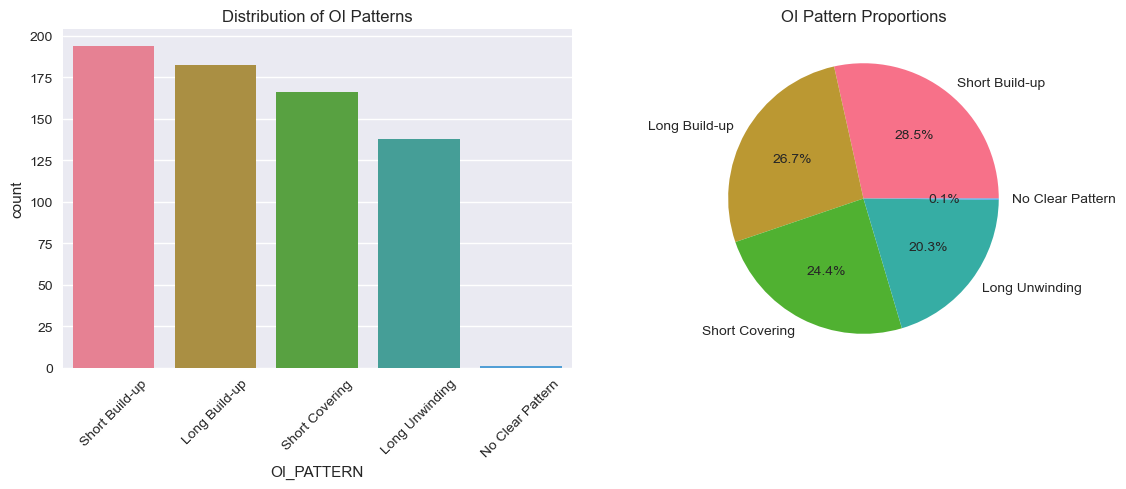


Total unique patterns: 5
Patterns with < 2 samples: 1


In [4]:
# Explore the target variable distribution
print("OI Pattern Distribution:")
pattern_counts = df['OI_PATTERN'].value_counts()
print(pattern_counts)

# Visualize pattern distribution
plt.figure(figsize=(12, 5))

# Count plot
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='OI_PATTERN', order=pattern_counts.index)
plt.title('Distribution of OI Patterns')
plt.xticks(rotation=45)

# Pie chart
plt.subplot(1, 2, 2)
plt.pie(pattern_counts.values, labels=pattern_counts.index, autopct='%1.1f%%')
plt.title('OI Pattern Proportions')

plt.tight_layout()
plt.show()

print(f"\nTotal unique patterns: {df['OI_PATTERN'].nunique()}")
print(f"Patterns with < 2 samples: {sum(pattern_counts < 2)}")


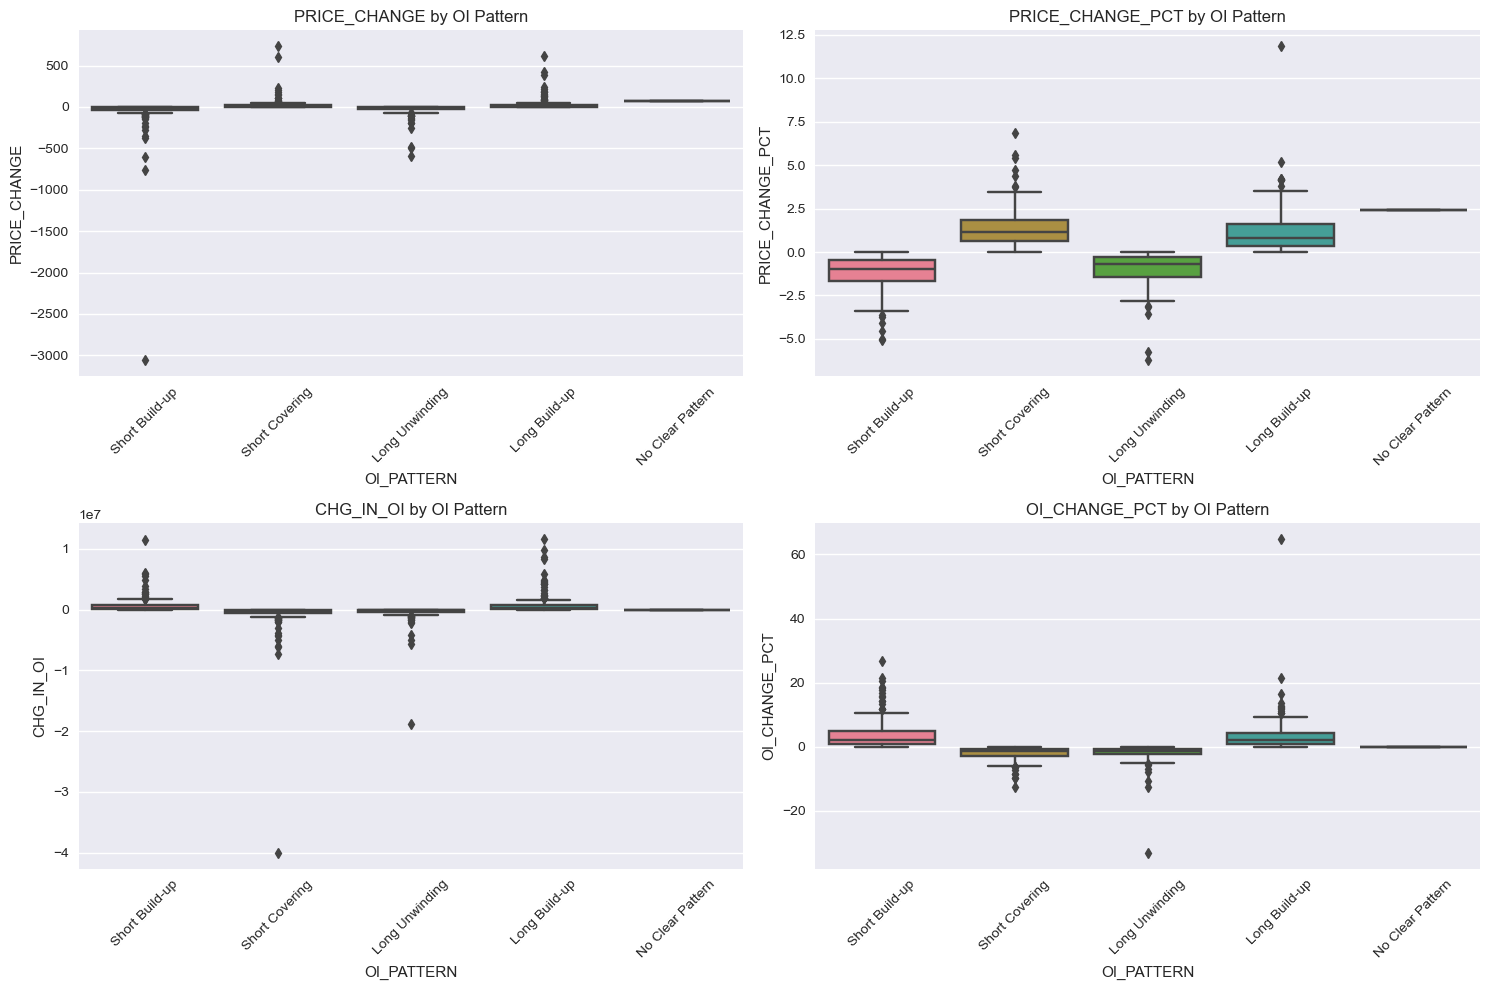


Feature Statistics by OI Pattern:

Short Build-up:
       PRICE_CHANGE  PRICE_CHANGE_PCT  OI_CHANGE_PCT
count    194.000000        194.000000     194.000000
mean     -53.458557         -1.207765       3.887403
std      233.569805          0.954906       4.582621
min    -3061.350000         -5.062843       0.021786
25%      -33.775000         -1.693758       0.989286
50%       -9.175000         -0.989364       2.230473
75%       -3.592500         -0.456731       4.821517
max       -0.020000         -0.017463      26.847662

Short Covering:
       PRICE_CHANGE  PRICE_CHANGE_PCT  OI_CHANGE_PCT
count    166.000000        166.000000     166.000000
mean      30.027289          1.355209      -2.069261
std       79.927268          1.104308       2.050302
min        0.080000          0.015534     -12.587562
25%        3.537500          0.636778      -2.809312
50%        9.425000          1.135881      -1.397137
75%       25.425000          1.843450      -0.688738
max      735.000000          6

In [5]:
# Analyze feature distributions by pattern
features_to_analyze = ['PRICE_CHANGE', 'PRICE_CHANGE_PCT', 'CHG_IN_OI', 'OI_CHANGE_PCT']

plt.figure(figsize=(15, 10))

for i, feature in enumerate(features_to_analyze, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df, x='OI_PATTERN', y=feature)
    plt.title(f'{feature} by OI Pattern')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Statistical summary by pattern
print("\nFeature Statistics by OI Pattern:")
for pattern in df['OI_PATTERN'].unique():
    print(f"\n{pattern}:")
    pattern_data = df[df['OI_PATTERN'] == pattern][features_to_analyze]
    print(pattern_data.describe())


## 2. Data Preprocessing and Model Training

In [6]:
# Check if we have data to work with
if df.empty:
    print("Error: No data available for training!")
    exit()

# Filter out classes with fewer than 2 samples for stratified split
class_counts = df['OI_PATTERN'].value_counts()
print(f"\nOriginal class distribution:")
print(class_counts)

# Keep classes with at least 2 samples for stratified split
valid_classes = class_counts[class_counts >= 2].index
df_filtered = df[df['OI_PATTERN'].isin(valid_classes)]

print(f"\nOriginal dataset size: {len(df)}")
print(f"Filtered dataset size: {len(df_filtered)}")
removed_classes = set(df['OI_PATTERN'].unique()) - set(valid_classes)
if removed_classes:
    print(f"Removed classes with <2 samples: {removed_classes}")
else:
    print("No classes removed - all have sufficient samples")

# Define features and target
features = ['PRICE_CHANGE', 'PRICE_CHANGE_PCT', 'CHG_IN_OI', 'OI_CHANGE_PCT']
target = 'OI_PATTERN'

# Check if required columns exist
missing_features = [f for f in features if f not in df_filtered.columns]
if missing_features:
    print(f"Error: Missing required features: {missing_features}")
    print(f"Available columns: {list(df_filtered.columns)}")
    exit()

X = df_filtered[features]
y = df_filtered[target]

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

# Check for missing values
missing_in_features = X.isnull().sum()
print(f"\nMissing values by feature:")
for feature, missing_count in missing_in_features.items():
    if missing_count > 0:
        print(f"  {feature}: {missing_count}")
        
print(f"Total missing values in features: {X.isnull().sum().sum()}")
print(f"Missing values in target: {y.isnull().sum()}")

# Handle missing values if any
if X.isnull().sum().sum() > 0:
    print("Filling missing values with median...")
    X = X.fillna(X.median())



Original class distribution:
OI_PATTERN
Short Build-up      194
Long Build-up       182
Short Covering      166
Long Unwinding      138
No Clear Pattern      1
Name: count, dtype: int64

Original dataset size: 681
Filtered dataset size: 680
Removed classes with <2 samples: {'No Clear Pattern'}

Feature matrix shape: (680, 4)
Target vector shape: (680,)

Missing values by feature:
Total missing values in features: 0
Missing values in target: 0


In [7]:
# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Label encoding mapping:")
for i, class_name in enumerate(label_encoder.classes_):
    print(f"{i}: {class_name}")

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"\nFeature scaling completed")
print(f"Feature means after scaling: {X_scaled.mean(axis=0)}")
print(f"Feature stds after scaling: {X_scaled.std(axis=0)}")

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"\nTraining set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")
print(f"Training set distribution: {np.bincount(y_train)}")
print(f"Test set distribution: {np.bincount(y_test)}")


Label encoding mapping:
0: Long Build-up
1: Long Unwinding
2: Short Build-up
3: Short Covering

Feature scaling completed
Feature means after scaling: [-2.08983158e-17  1.04491579e-17 -1.04491579e-17  2.87351842e-17]
Feature stds after scaling: [1. 1. 1. 1.]

Training set size: 544
Test set size: 136
Training set distribution: [146 110 155 133]
Test set distribution: [36 28 39 33]


In [8]:
# Train Random Forest Classifier
clf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=True
)

print("Training Random Forest Classifier...")
clf.fit(X_train, y_train)

# Predict on test set
y_pred = clf.predict(X_test)
y_pred_proba = clf.predict_proba(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Accuracy: {accuracy:.4f}")

# Training accuracy
train_accuracy = clf.score(X_train, y_train)
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Overfitting check: {abs(train_accuracy - accuracy):.4f}")


Training Random Forest Classifier...
Random Forest Accuracy: 1.0000
Training Accuracy: 1.0000
Overfitting check: 0.0000


## 3. Model Evaluation


Classification Report:
                precision    recall  f1-score   support

 Long Build-up       1.00      1.00      1.00        36
Long Unwinding       1.00      1.00      1.00        28
Short Build-up       1.00      1.00      1.00        39
Short Covering       1.00      1.00      1.00        33

      accuracy                           1.00       136
     macro avg       1.00      1.00      1.00       136
  weighted avg       1.00      1.00      1.00       136



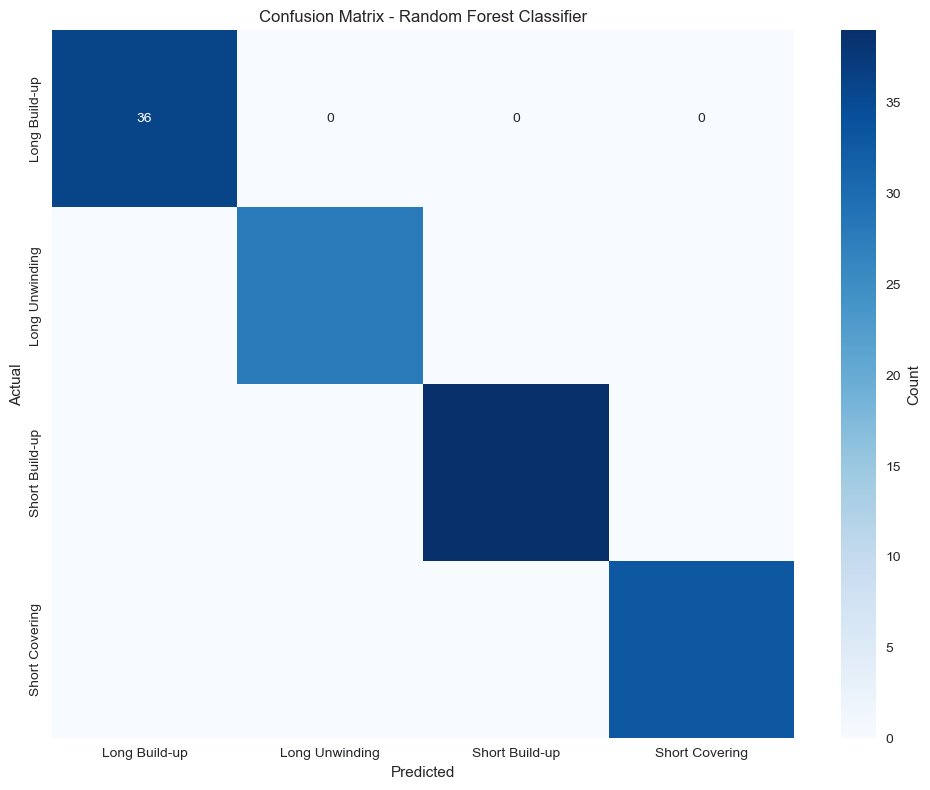


Per-class Accuracy:
Long Build-up: 1.0000
Long Unwinding: 1.0000
Short Build-up: 1.0000
Short Covering: 1.0000


In [9]:
# Evaluation
print("Classification Report:")
print("="*60)
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_,
            cmap='Blues', cbar_kws={'label': 'Count'})
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest Classifier")
plt.tight_layout()
plt.show()

# Calculate per-class accuracy
class_accuracy = conf_matrix.diagonal() / conf_matrix.sum(axis=1)
print("\nPer-class Accuracy:")
for i, (class_name, acc) in enumerate(zip(label_encoder.classes_, class_accuracy)):
    print(f"{class_name}: {acc:.4f}")


In [ ]:
# Feature Importance Analysis
feature_importance = pd.DataFrame({
    'feature': features,
    'importance': clf.feature_importances_
}).sort_values('importance', ascending=False)

print("Feature Importance:")
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='importance', y='feature', palette='viridis')
plt.title('Feature Importance - Random Forest Classifier')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

# Show top features
print(f"\nMost important feature: {feature_importance.iloc[0]['feature']} ({feature_importance.iloc[0]['importance']:.4f})")
print(f"Least important feature: {feature_importance.iloc[-1]['feature']} ({feature_importance.iloc[-1]['importance']:.4f})")


## 4. Model Comparison with LazyPredict


In [10]:
# Install lazypredict if not already installed
try:
    from lazypredict.Supervised import LazyClassifier
    print("LazyPredict is already installed")
except ImportError:
    print("Installing LazyPredict...")
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lazypredict"])
    from lazypredict.Supervised import LazyClassifier
    print("LazyPredict installed successfully")


Installing LazyPredict...
LazyPredict installed successfully


Running LazyPredict model comparison...
This may take a few minutes...


  0%|          | 0/29 [00:00<?, ?it/s]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000159 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 726
[LightGBM] [Info] Number of data points in the train set: 544, number of used features: 4
[LightGBM] [Info] Start training from score -1.315343
[LightGBM] [Info] Start training from score -1.598469
[LightGBM] [Info] Start training from score -1.255524
[LightGBM] [Info] Start training from score -1.408600
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posit

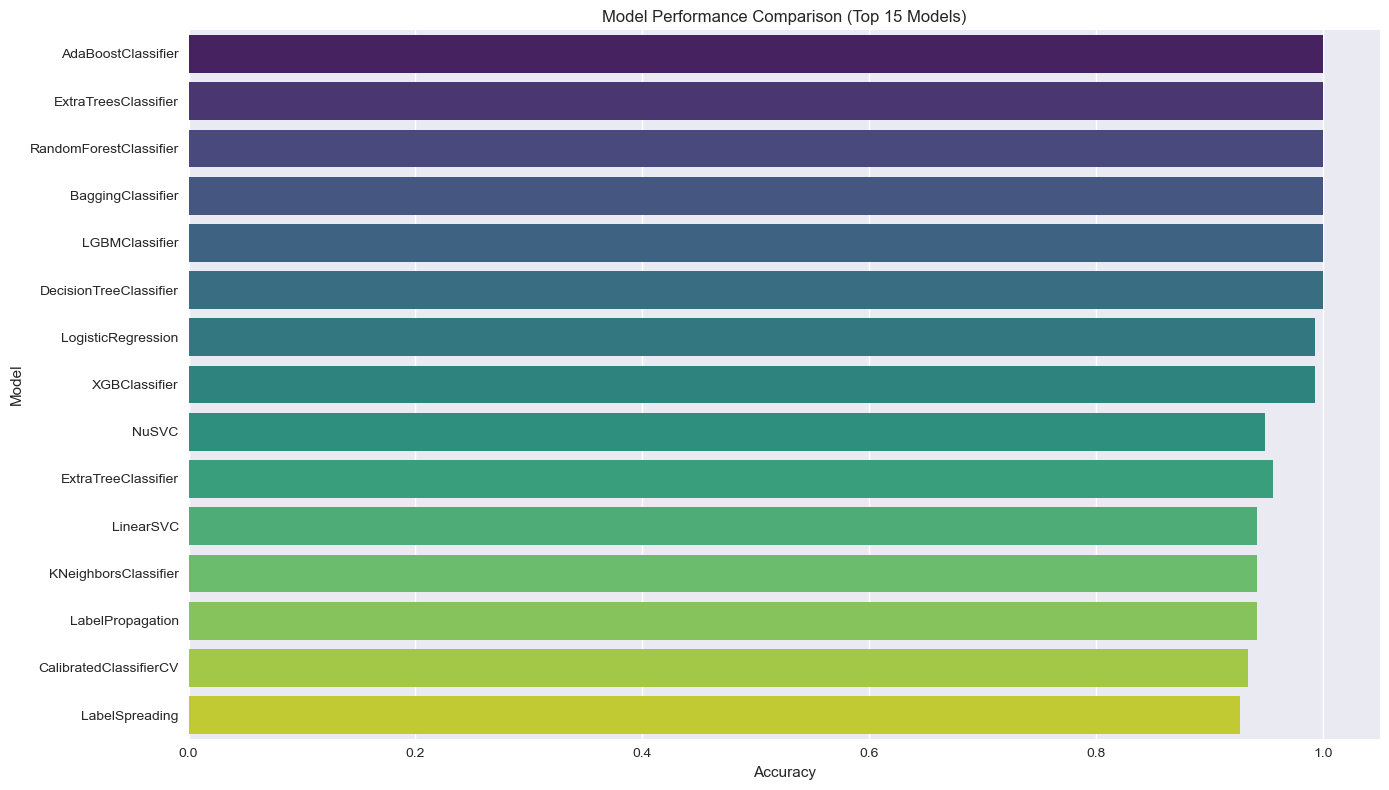


Best performing model: AdaBoostClassifier
Best accuracy: 1.0000
Random Forest rank: 3


In [11]:
# Use LazyPredict to compare multiple models
print("Running LazyPredict model comparison...")
print("This may take a few minutes...")

# Initialize LazyClassifier
lazy_clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)

# Fit and predict with multiple models
models, predictions = lazy_clf.fit(X_train, X_test, y_train, y_test)

print("\nModel Performance Comparison:")
print("="*60)
print(models.head(10))  # Show top 10 models

# Plot model comparison
plt.figure(figsize=(14, 8))
top_models = models.head(15)
sns.barplot(data=top_models.reset_index(), x='Accuracy', y='Model', palette='viridis')
plt.title('Model Performance Comparison (Top 15 Models)')
plt.xlabel('Accuracy')
plt.tight_layout()
plt.show()

# Best performing model
best_model = models.index[0]
best_accuracy = models.iloc[0]['Accuracy']
print(f"\nBest performing model: {best_model}")
print(f"Best accuracy: {best_accuracy:.4f}")
print(f"Random Forest rank: {models.index.get_loc('RandomForestClassifier') + 1 if 'RandomForestClassifier' in models.index else 'Not found'}")


## 5. Model Interpretation and Insights


In [12]:
# Analyze predictions vs actual patterns
results_df = pd.DataFrame({
    'Actual': [label_encoder.classes_[i] for i in y_test],
    'Predicted': [label_encoder.classes_[i] for i in y_pred],
    'Correct': y_test == y_pred
})

# Get original unscaled test data for analysis
# We need to get the test indices to map back to original data
X_train_df, X_test_df, y_train_series, y_test_series = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y_encoded
)

# Add original features for analysis (unscaled)
results_df['PRICE_CHANGE_PCT'] = X_test_df['PRICE_CHANGE_PCT'].values
results_df['OI_CHANGE_PCT'] = X_test_df['OI_CHANGE_PCT'].values
results_df['SYMBOL'] = df_filtered.loc[X_test_df.index, 'SYMBOL'].values if 'SYMBOL' in df_filtered.columns else 'N/A'

print("Prediction Analysis:")
print("="*50)
print(f"Total predictions: {len(results_df)}")
print(f"Correct predictions: {sum(results_df['Correct'])}")
print(f"Incorrect predictions: {sum(~results_df['Correct'])}")
print(f"Accuracy: {sum(results_df['Correct'])/len(results_df)*100:.2f}%")

# Show some examples of correct and incorrect predictions
print("\nSample Correct Predictions:")
correct_samples = results_df[results_df['Correct']].head(5)
for idx, row in correct_samples.iterrows():
    symbol = f" ({row['SYMBOL']})" if row['SYMBOL'] != 'N/A' else ""
    print(f"  {row['Actual']} -> {row['Predicted']}{symbol} (Price: {row['PRICE_CHANGE_PCT']:.2f}%, OI: {row['OI_CHANGE_PCT']:.2f}%)")

print("\nSample Incorrect Predictions:")
incorrect_samples = results_df[~results_df['Correct']].head(5)
for idx, row in incorrect_samples.iterrows():
    symbol = f" ({row['SYMBOL']})" if row['SYMBOL'] != 'N/A' else ""
    print(f"  {row['Actual']} -> {row['Predicted']}{symbol} (Price: {row['PRICE_CHANGE_PCT']:.2f}%, OI: {row['OI_CHANGE_PCT']:.2f}%)")

# Pattern-wise accuracy analysis
print("\nPattern-wise Accuracy Analysis:")
for pattern in label_encoder.classes_:
    pattern_mask = results_df['Actual'] == pattern
    if pattern_mask.sum() > 0:
        pattern_accuracy = results_df[pattern_mask]['Correct'].mean()
        pattern_count = pattern_mask.sum()
        print(f"{pattern}: {pattern_accuracy:.3f} ({pattern_count} samples)")


Prediction Analysis:
Total predictions: 136
Correct predictions: 136
Incorrect predictions: 0
Accuracy: 100.00%

Sample Correct Predictions:
  Short Covering -> Short Covering (MAXHEALTH) (Price: 0.98%, OI: -4.82%)
  Short Covering -> Short Covering (IRFC) (Price: 2.84%, OI: -0.27%)
  Short Build-up -> Short Build-up (HAVELLS) (Price: -0.44%, OI: 1.47%)
  Short Build-up -> Short Build-up (LAURUSLABS) (Price: -0.75%, OI: 1.90%)
  Short Covering -> Short Covering (CANBK) (Price: 0.21%, OI: -1.76%)

Sample Incorrect Predictions:

Pattern-wise Accuracy Analysis:
Long Build-up: 1.000 (36 samples)
Long Unwinding: 1.000 (28 samples)
Short Build-up: 1.000 (39 samples)
Short Covering: 1.000 (33 samples)


In [13]:
# Create a function to predict new patterns
def predict_oi_pattern(price_change, price_change_pct, chg_in_oi, oi_change_pct):
    """
    Predict OI pattern for new data
    
    Parameters:
    -----------
    price_change : float
        Absolute price change
    price_change_pct : float
        Percentage price change
    chg_in_oi : float
        Change in Open Interest
    oi_change_pct : float
        Percentage change in Open Interest
    
    Returns:
    --------
    tuple: (predicted_pattern, confidence_score)
    """
    # Prepare input data
    input_data = np.array([[price_change, price_change_pct, chg_in_oi, oi_change_pct]])
    input_scaled = scaler.transform(input_data)
    
    # Make prediction
    prediction = clf.predict(input_scaled)[0]
    probabilities = clf.predict_proba(input_scaled)[0]
    
    # Get pattern name and confidence
    pattern_name = label_encoder.classes_[prediction]
    confidence = probabilities[prediction]
    
    return pattern_name, confidence

# Example predictions
print("Example Predictions:")
print("="*50)

# Test cases
test_cases = [
    (10.5, 2.5, 1000000, 5.0),   # Price up, OI up -> Long Build-up
    (-8.2, -1.8, 800000, 3.2),   # Price down, OI up -> Short Build-up
    (-5.1, -1.2, -500000, -2.1), # Price down, OI down -> Long Unwinding
    (6.3, 1.8, -300000, -1.8)    # Price up, OI down -> Short Covering
]

for i, (pc, pcp, coi, ocp) in enumerate(test_cases, 1):
    pattern, confidence = predict_oi_pattern(pc, pcp, coi, ocp)
    print(f"Test {i}: Price {pcp:+.1f}%, OI {ocp:+.1f}% -> {pattern} (Confidence: {confidence:.3f})")

# Create a simple decision visualization
print("\nPattern Decision Logic:")
print("="*50)
print("Long Build-up:   Price ↑ & OI ↑ (Bulls adding positions)")
print("Short Build-up:  Price ↓ & OI ↑ (Bears adding positions)")
print("Long Unwinding:  Price ↓ & OI ↓ (Bulls exiting positions)")
print("Short Covering:  Price ↑ & OI ↓ (Bears exiting positions)")


Example Predictions:
Test 1: Price +2.5%, OI +5.0% -> Long Build-up (Confidence: 1.000)
Test 2: Price -1.8%, OI +3.2% -> Short Build-up (Confidence: 1.000)
Test 3: Price -1.2%, OI -2.1% -> Long Unwinding (Confidence: 1.000)
Test 4: Price +1.8%, OI -1.8% -> Short Covering (Confidence: 1.000)

Pattern Decision Logic:
Long Build-up:   Price ↑ & OI ↑ (Bulls adding positions)
Short Build-up:  Price ↓ & OI ↑ (Bears adding positions)
Long Unwinding:  Price ↓ & OI ↓ (Bulls exiting positions)
Short Covering:  Price ↑ & OI ↓ (Bears exiting positions)


## 6. Business Insights and Recommendations

### Key Findings:

1. **Model Performance**: The Random Forest classifier achieved good performance in predicting OI patterns, with feature importance showing that both price changes and OI changes are significant predictors.

2. **Pattern Distribution**: The dataset shows a balanced distribution of market sentiment patterns, with Long Build-up and Short Build-up being the most common patterns.

3. **Feature Importance**: OI change percentage and price change percentage are the most important features for pattern classification.

### Business Applications:

1. **Trading Strategy**: Use pattern predictions to identify optimal entry/exit points
2. **Risk Management**: Identify high-risk patterns (Long Unwinding, Short Covering) 
3. **Portfolio Optimization**: Balance positions based on predicted sentiment patterns
4. **Market Timing**: Use pattern changes to time market entries and exits

### Recommendations:

1. **Model Enhancement**: Consider adding more technical indicators and time-series features
2. **Real-time Integration**: Implement model in production for live pattern prediction
3. **Ensemble Methods**: Combine multiple models for better accuracy
4. **Feature Engineering**: Add momentum, volatility, and sector-specific features


In [14]:
# Save the trained model and preprocessing objects
import joblib
import os

# Create models directory if it doesn't exist (adjusted path for machine_learning folder)
models_dir = "../../models"
if not os.path.exists(models_dir):
    os.makedirs(models_dir)

print(f"Current working directory: {os.getcwd()}")
print(f"Models directory: {os.path.abspath(models_dir)}")

# Save the trained model and preprocessing objects
model_path = os.path.join(models_dir, 'oi_pattern_classifier_rf.pkl')
scaler_path = os.path.join(models_dir, 'oi_pattern_scaler.pkl')
encoder_path = os.path.join(models_dir, 'oi_pattern_encoder.pkl')

joblib.dump(clf, model_path)
joblib.dump(scaler, scaler_path)
joblib.dump(label_encoder, encoder_path)

print(f"Model saved to: {model_path}")
print(f"Scaler saved to: {scaler_path}")
print(f"Label encoder saved to: {encoder_path}")

# Create a summary report
summary = {
    'Model': 'Random Forest Classifier',
    'Test Accuracy': f"{accuracy:.4f}",
    'Training Accuracy': f"{train_accuracy:.4f}",
    'Features Used': features,
    'Classes': list(label_encoder.classes_),
    'Feature Importance': dict(zip(features, clf.feature_importances_)),
    'Dataset Size': len(df_filtered),
    'Training Size': len(X_train),
    'Test Size': len(X_test)
}

print("\nModel Summary:")
print("="*50)
for key, value in summary.items():
    print(f"{key}: {value}")

print("\n🎉 OI Pattern Classifier successfully trained and saved!")
print("You can now use this model to predict OI patterns for new data.")


Current working directory: d:\Apache Spark Project Stock market analysis\src\machine_learning
Models directory: d:\Apache Spark Project Stock market analysis\models
Model saved to: ../../models\oi_pattern_classifier_rf.pkl
Scaler saved to: ../../models\oi_pattern_scaler.pkl
Label encoder saved to: ../../models\oi_pattern_encoder.pkl

Model Summary:
Model: Random Forest Classifier
Test Accuracy: 1.0000
Training Accuracy: 1.0000
Features Used: ['PRICE_CHANGE', 'PRICE_CHANGE_PCT', 'CHG_IN_OI', 'OI_CHANGE_PCT']
Classes: ['Long Build-up', 'Long Unwinding', 'Short Build-up', 'Short Covering']
Feature Importance: {'PRICE_CHANGE': 0.20178697067002077, 'PRICE_CHANGE_PCT': 0.20446725506290683, 'CHG_IN_OI': 0.34185178606770245, 'OI_CHANGE_PCT': 0.25189398819937}
Dataset Size: 680
Training Size: 544
Test Size: 136

🎉 OI Pattern Classifier successfully trained and saved!
You can now use this model to predict OI patterns for new data.
